In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import scipy
import glob
import pathlib
import datetime
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
import string
letters = string.ascii_lowercase

import helpers
import plot_helpers
import analytical

paperdir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/figures/paper')
paperdir.mkdir(parents=1, exist_ok=1)

#### LOAD

In [2]:
# load data

datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_resubmission/data/statistics_L2')
ds_flist = sorted(list(datadir.glob('*.nc')))
li = []
for i in range(len(ds_flist)):
    ds = xr.open_dataset(ds_flist[i])
    li.append(ds)
ds = xr.concat(li, dim='system')
print('We have', ds.system.size, 'DCCs')

# filter
gsystems = ds.max_CMF.dropna('system', how='all').system
ds = ds.sel(system=[x for x in ds.system.values if x in gsystems])
print('Of these,', ds.system.size, 'were good quality')

ds = ds.where(ds.lifestages_valid).dropna('system', how='all')
print('Of these,', ds.system.size, 'had all valid lifestages')

print((ds.ncores==1).sum().item(), 'had one core')
print((ds.ncores>1).sum().item(), 'had more than one core')

We have 5367 DCCs
Of these, 5334 were good quality
Of these, 5110 had all valid lifestages
3922 had one core
1188 had more than one core


In [3]:
# calculate intensity quartiles

intensity_measures = ['total_CMT','max_CMT','max_CMF','max_w','max_Ac','conv_lifetime',
                      'col_max_w', 'core_max_pr','cloud_min_tt']
df = helpers.dccs_by_intensity_metrics(ds, ds[intensity_measures])

In [4]:
# define a global colormap
CMAP = mpl.colors.ListedColormap(plt.get_cmap('Reds')(np.linspace(.25,1,265)))
HCMAP = mpl.colors.ListedColormap(plt.get_cmap("cividis")(np.linspace(0.25, 1, 256)))

# choices
dpi = 300
ext = 'pdf'
fs = 12
key = 'total_CMT'

# labels for key variables
global_labels = {"total_CMT":r"$\int M_c dt\,$ [kg s$^{-1}$]",
                 "total_CMT_l60":r"$\int M_c dt\,$",
                 "max_CMT":r"$M_{c,max}$",
                 "max_CMF":r"$(\rho w)_{max}$",
                 "mean_CMF":r"$(\rho w)_{mean}$ [kg m$^{-2}$ s$^{-1}$]",
                 "max_w":r"$w_{max}$ [m s$^1$]",
                 "col_max_w":r"$w_{max}$",
                 "max_Ac":r"$A_c$ [m$^2$]",
                 "core_max_pr":r"$pr_{max}$",
                 "cloud_min_tt": r"$T_{b,min}$",
                 "conv_lifetime":r"$t_c$ [hr]",
                 "Apred_v1":r'$\frac{1}{D\bar{\rho}}\int M_{c,max}\,dt$',
                 "Apred_v2":r'$\int \frac{M_c}{D\bar{\rho}}\,dt$',
                }

#### FIGURE 1

In [6]:
# load snapshot

results_dir = pathlib.Path('/work/bb1153/b382635/data/final_tracks/dcc_frozen_1e4/tropics')
map_ds = xr.open_mfdataset(results_dir.glob('*/*system_tracks_linked.nc')).isel(time=slice(0,None))
map_ds = map_ds.where(map_ds>0)

utc = '202107011800'
ice = map_ds.system
pdata = ice.sel(time=utc).expand_dims('time')
pdata = pdata.compute()

In [7]:
# plot prep

map_dpi = 100

def make_repeated_tab20_colorbar(x):
    base = plt.get_cmap("tab20").colors
    colors = [base[i % len(base)] for i in range(x)]
    cmap = mpl.colors.ListedColormap(colors, name=f"repeated_tab20_{x}")
    norm = mpl.colors.BoundaryNorm(np.arange(-0.5, x + 0.5, 1), cmap.N)
    return cmap

vmax = pdata.max().values
cmap = make_repeated_tab20_colorbar(int(vmax))

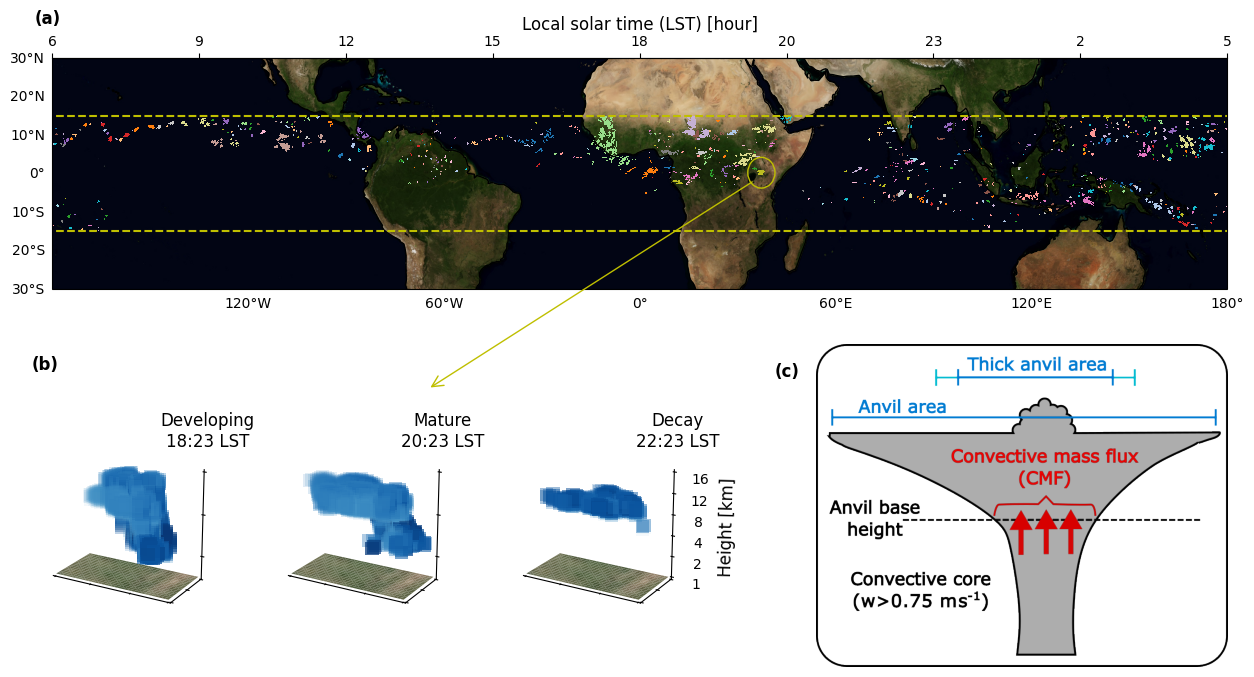

In [8]:
# plot

tstr = pdata.sel(time=utc).time.dt.strftime('%Y%m%dT%H%M').item()
fpath = paperdir / f'fig01_{tstr}.{ext}'
    
# --- layout ---
proj = ccrs.Robinson()
nlon = 360
nlat = 60
scale = 0.05
fig, ax = plt.subplots(figsize=(nlon*scale, nlat*scale), subplot_kw=dict(projection=proj))

## 1. plot tropics
ax = plot_helpers.make_map(ax, pdata, utc, cmap, vmax, fs)
ax.text(-.015, 1.15, '(a)', fontsize=fs, weight='bold', c='k', transform=ax.transAxes)

## 2. show example
t1 = datetime.datetime.strptime(utc, '%Y%m%d%H%M')
t0 = t1 - datetime.timedelta(hours=2)
t2 = t1 + datetime.timedelta(hours=2)

sidx = 3876
example_data = ice.sel(time=[t0,t1,t2])
example_data = example_data.where(example_data == sidx).dropna('lat', how='all').dropna('lon', how='all')

dws = [0,0,0]
dcs = [1,1,1]
name = ("Developing", "Mature", "Decay")
for j, t in enumerate((t0,t1,t2)):
    # axes
    pc = ccrs.PlateCarree()
    bbox = ax.get_position()
    inset_w = bbox.width / 3 * 0.6
    inset_h = bbox.height * .8
    inset_x = bbox.x0 + inset_w * j - .025
    inset_y = bbox.y0 - 1.1
    inset_ax = fig.add_axes([inset_x, inset_y, inset_w, inset_h], projection='3d')
    if not j:
        inset_ax.text2D(0, 1.35, '(b)', fontsize=fs, weight='bold', c='k', transform=inset_ax.transAxes)
    # data
    d = example_data.sel(time=t).expand_dims('time')
    inset_ax = plot_helpers.make_example(inset_ax, d, t, show_dc=dcs[j], show_dw=dws[j], zaxis=j==2, haxis=0, name=name[j])
    inset_ax.set_xlim(d.lon.min(), d.lon.max())
    inset_ax.set_ylim(d.lat.min(), d.lat.max())
    
# circle
radius = 4
clon = example_data.lon.mean()
clat = example_data.lat.mean()
ax.add_patch(Circle((clon, clat), radius=radius, transform=pc, fill=False, ec='y', lw=1, zorder=20,))

# line
pt_data = proj.transform_point(clon-radius/2, clat-radius/2, pc)
pt_disp = ax.transData.transform(pt_data)
pt_fig = fig.transFigure.inverted().transform(pt_disp)
inset_pos = inset_ax.get_position()
x2 = bbox.x0 + inset_w * 1.6
y2 = inset_pos.y1 + .15
fig.add_artist(mpl.patches.FancyArrowPatch((pt_fig[0], pt_fig[1]),(x2, y2), transform=fig.transFigure, arrowstyle='->', color='y', mutation_scale=20, zorder=15,))

## 3. show method

img = plt.imread("/home/b/b382635/s/my_notebooks/model_paper/grl_submission/scripts/fig01_diagram.png")

bbox = ax.get_position()
inset_w = bbox.width * 0.35
inset_h = bbox.height * 1.5
inset_x = bbox.x1 - inset_w
inset_y = bbox.y0 - 1.3
ax_img = fig.add_axes([inset_x, inset_y, inset_w, inset_h])
ax_img.imshow(img)
ax_img.axis('off')
ax_img.text(-.1, .9, '(c)', fontsize=fs, weight='bold', c='k', transform=ax_img.transAxes)

## 4. SAVE
fig.savefig(paperdir / f'fig01.{ext}', dpi=map_dpi, bbox_inches='tight')

#### FIGURE 2

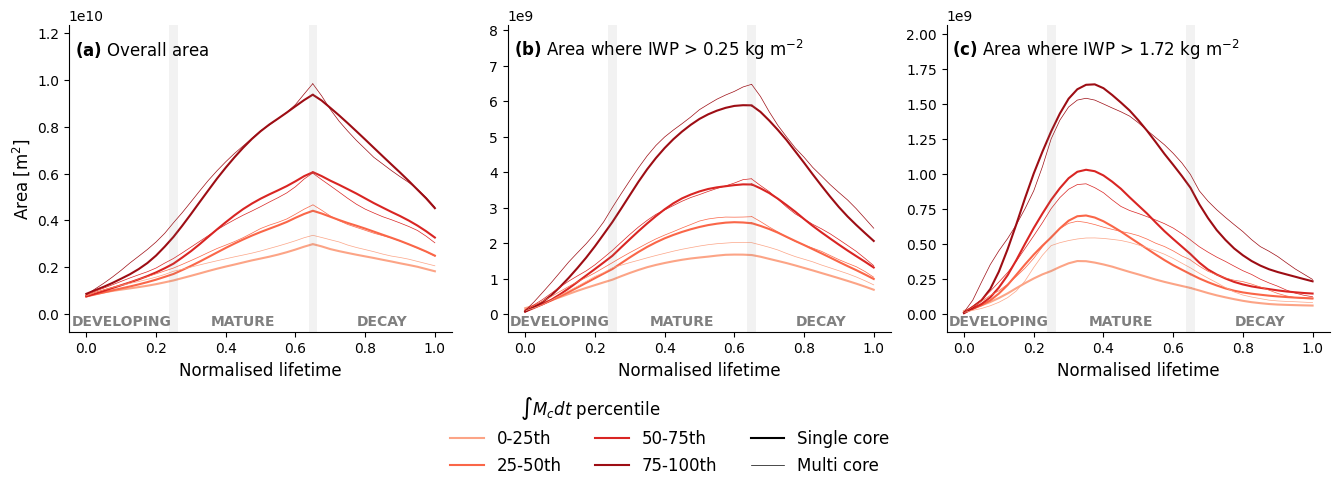

In [56]:
# data
thresholds = [4, 8]
phases = ["developing", "mature", "decay"]

# process — include both ncores==1 and ncores>1
pds = ds[["cloud_area", "anvil_area", "thick_area", "ncores"]]
pdata_single = helpers.group_dataset_by_intensity(
    pds.where(pds.ncores == 1), df, apply=lambda x: x.mean("system", keep_attrs=True)
)["total_CMT"]
pdata_multi = helpers.group_dataset_by_intensity(
    pds.where(pds.ncores > 1), df, apply=lambda x: x.mean("system", keep_attrs=True)
)["total_CMT"]

# figure
nplots = len(thresholds) + 1
fig, axs = plt.subplots(1, nplots, figsize=(nplots * 4.5, 4), layout="tight")
axs = np.atleast_1d(axs)

handles = None
labels = None

for i, ax in enumerate(axs):

    for pdata, lw in [(pdata_single, 1.5), (pdata_multi, 0.5)]:
        is_single = lw == 1.5
        line_lo = None
        line_hi = None

        if i == 0:
            data = pdata.cloud_area.sel(phase=phases)
            threshold_label = None
        else:
            threshold = thresholds[i - 1]
            data = pdata.thick_area.sel(phase=phases).isel(threshold=threshold)
            threshold_label = data.threshold

        for j, b in enumerate(pdata.bins.values):
            color = CMAP(j / 4 + 0.1)
            evolution = plot_helpers.get_evolution(data.sel(bins=b))
            line = evolution.plot(
                ax=ax, c=color, lw=lw,
                label=f"{b}th" if is_single else None,  # label only once
            )

            if j == 0:
                line_lo = line[0]
            if j == len(pdata.bins.values) - 1:
                line_hi = line[0]

        if lw == 1:
            y_lo = line_lo.get_ydata().max()
            x_lo = line_lo.get_xdata()[line_lo.get_ydata().argmax()]
            y_hi = line_hi.get_ydata().max()
            x_hi = line_hi.get_xdata()[line_hi.get_ydata().argmax()]
    
            plot_helpers.annotate_arrow(ax, 0.9 if is_single else 0.75, y_lo, y_hi, x_lo=x_lo, x_hi=x_hi)

    plot_helpers.show_phases(ax)

    title = (
        rf"$\mathbf{{({letters[i]})}}$ Overall area"
        if i == 0
        else rf"$\mathbf{{({letters[i]})}}$ Area where IWP > {threshold_label:.2f} kg m$^{{-2}}$"
    )
    ax.text(0.015, 0.9, title, c="k", fontsize=fs, transform=ax.transAxes)

    ax.set_xlabel("Normalised lifetime", fontsize=fs)
    ax.set_ylabel("Area [m$^2$]" if i == 0 else None, fontsize=fs)
    ax.set_title(None)

    ymax = ax.get_ylim()[1]
    ax.set_ylim(ymax * -0.075, ymax * 1.2)
    ax.spines[["top", "right"]].set_visible(False)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

lw_handles = [
    mpl.lines.Line2D([], [], color="k", lw=1.5, label="Single core"),
    mpl.lines.Line2D([], [], color="k", lw=0.5, label="Multi core"),
]
lw_labels = [h.get_label() for h in lw_handles]

legend = fig.legend(
    handles+lw_handles,
    labels+lw_labels,
    title=r"$\int M_c dt$ percentile                               ",
    fontsize=fs,
    loc="center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
    frameon=False,
)
legend.get_title().set_fontsize(fs)

fig.savefig(paperdir / f"fig02.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)

#### FIGURE 3

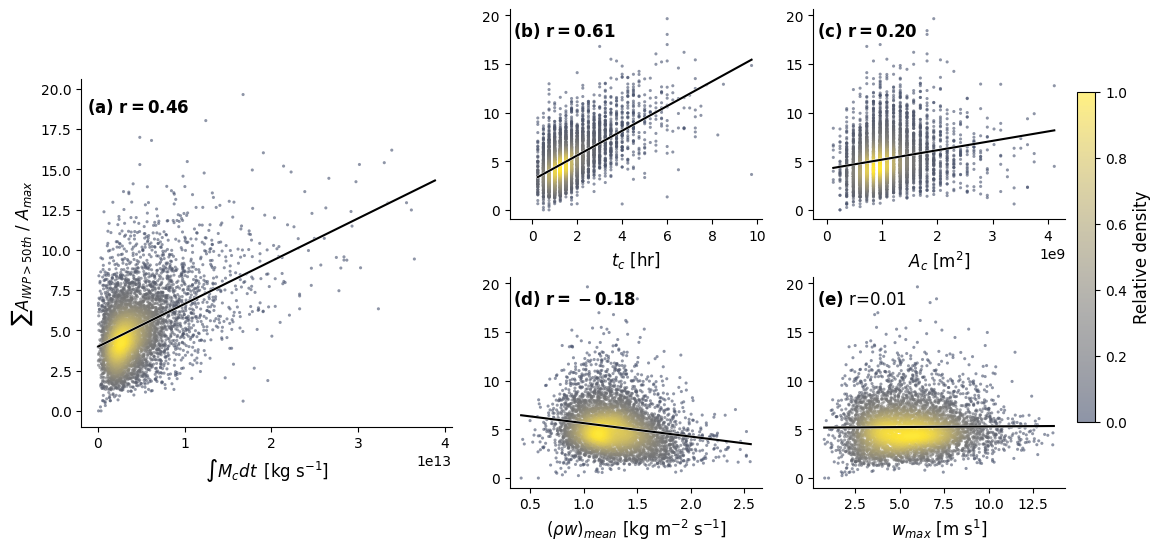

In [99]:
metrics = ["total_CMT", "conv_lifetime", "max_Ac", "mean_CMF", "max_w", ]
# metrics = ["total_CMT", "conv_lifetime", "mean_CMF", "core_max_pr", "max_w", "max_Ac", "cloud_min_tt" ]

di = {'all': [ds.ncores>0, dict(label=None, c='k')],
      'single': [ds.ncores==1, dict(label=None, c='k')],
      'multi': [ds.ncores>1, dict(label=None, c='grey')]}

fig = plt.figure(figsize=(12,5.5))

grid = (2, 2)
nrows, ncols = grid
axs = [None] * (1 + nrows * ncols)

outer = mpl.gridspec.GridSpec(1, 2, figure=fig, wspace=0.125, width_ratios=[1, 1.5],
                              left=0.08, right=.9, top=0.95, bottom=0.08)

left_gs = outer[0].subgridspec(3, 1, height_ratios=[.2, 1, .175], hspace=0)
axs[0] = fig.add_subplot(left_gs[1])
inner = outer[1].subgridspec(nrows, ncols, hspace=0.275, wspace=0.2)
for i in range(nrows * ncols):
    sharey = axs[1] if i > 0 else None
    axs[i + 1] = fig.add_subplot(inner[i // ncols, i % ncols], sharey=sharey)

for i,ax in enumerate(axs):
    Y = ds["total_thick_area"].isel(threshold=4) / ds["max_anvil_area"]
    ylab = "$\sum A_{IWP>50th}$ / $A_{max}$"
        
    li = di['all']
    metric = metrics[i%len(metrics)]
    x = ds.where(li[0])[metric]
    y = Y.where(li[0])

    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    lo, hi = np.percentile(x, [0, 99.95])
    mask_pct = (x >= lo) & (x <= hi)
    x, y = x[mask_pct], y[mask_pct]
    m, b, r, p, _ = scipy.stats.linregress(x, y)
    x_fit = np.array([lo, hi])

    density = scipy.stats.gaussian_kde(np.vstack([x, y]))(np.vstack([x, y]))
    density = (density - density.min()) / (density.max() - density.min())
    order = density.argsort()
    sc = axs[i].scatter(x[order], y[order], c=density[order], s=5,
                        cmap=HCMAP, alpha=0.6, rasterized=True, linewidths=0)

    label = rf"$\mathbf{{r={r:.2f}}}$" if p < 0.05 else rf"r={r:.2f}"
    axs[i].plot(x_fit, m * x_fit + b, c='w', lw=2)
    axs[i].plot(x_fit, m * x_fit + b, c='k', lw=1.5, label=label)

    ax.set_xlabel(global_labels[metric], fontsize=fs)
    ax.spines[["top", "right"]].set_visible(False)

    letter = letters[i]
    ax.text(0.015, 0.95, rf"$\mathbf{{({letter})}}$ "+label, transform=ax.transAxes, fontsize=fs, va="top")

    if i in [0,len(metrics)]:
        ax.set_ylabel(ylab, fontsize=fs)

axs[1].set_xlim(-1,None)
axs[2].set_xlim(-.25e9,None)

cax = fig.add_axes([0.91, 0.2, 0.015, 0.6])  # [left, bottom, width, height]
cb = fig.colorbar(sc, cax=cax)
cb.set_label('Relative density', fontsize=fs)

fig.savefig(paperdir / f"fig03.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


#### FIGURE 4 NEW

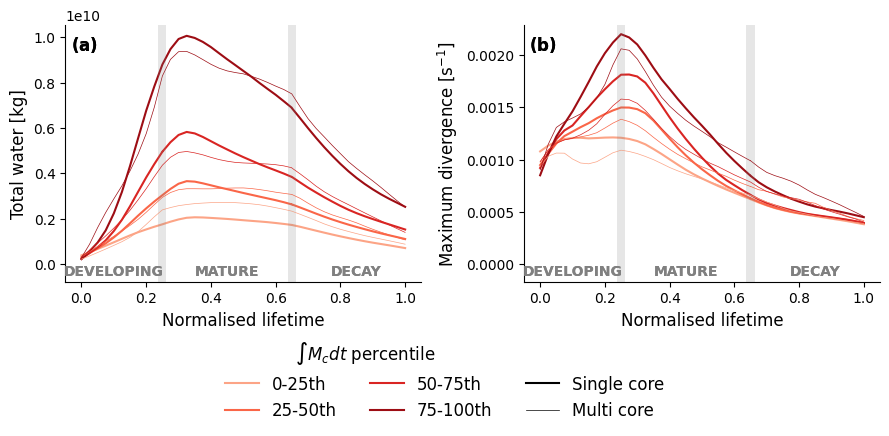

In [62]:
# data
variables = ["anvil_tw", "anvil_div_max"]
ylabels = ["Total water [kg]", "Maximum divergence [s$^{-1}$]"]
phases = ["developing", "mature", "decay"]

pds = ds[variables + ["ncores",]]
pdata_single = helpers.group_dataset_by_intensity(
    pds.where(pds.ncores == 1), df, apply=lambda x: x.mean("system", keep_attrs=True)
)["total_CMT"]
pdata_multi = helpers.group_dataset_by_intensity(
    pds.where(pds.ncores > 1), df, apply=lambda x: x.mean("system", keep_attrs=True)
)["total_CMT"]

# figure
nplots = len(variables)
fig, axs = plt.subplots(1, nplots, figsize=(nplots * 4.5, 3.5), layout="tight")
axs = np.atleast_1d(axs)

handles = None
labels = None
        
for pdata, lw in [(pdata_single, 1.5), (pdata_multi, 0.5)]:
    is_single = lw == 1.5

    for i, ax in enumerate(axs):
        data = pdata[variables[i]].sel(phase=phases)

        for j, b in enumerate(pdata.bins.values):
            color = CMAP(j / 4 + 0.1)
            evolution = plot_helpers.get_evolution(data.sel(bins=b))
            line = evolution.plot(
                ax=ax, c=color, lw=lw,
                label=f"{b}th" if is_single else None,  # label only once
            )
                
        title = rf"$\mathbf{{({letters[i]})}}$"
        ax.text(0.015, 0.9, title, c="k", fontsize=fs, transform=ax.transAxes)
        plot_helpers.show_phases(ax)
        ax.set_title(None)
        ax.set_xlabel("Normalised lifetime", fontsize=fs)
        ax.set_ylabel(ylabels[i], fontsize=fs)        
        ymax = ax.get_ylim()[1]
        ax.set_ylim(ymax * -0.075, None)
        ax.spines[["top", "right"]].set_visible(False)
        
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

lw_handles = [
    mpl.lines.Line2D([], [], color="k", lw=1.5, label="Single core"),
    mpl.lines.Line2D([], [], color="k", lw=0.5, label="Multi core"),
]
lw_labels = [h.get_label() for h in lw_handles]

legend = fig.legend(
    handles+lw_handles,
    labels+lw_labels,
    title=r"$\int M_c dt$ percentile                               ",
    fontsize=fs,
    loc="center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
    frameon=False,
)
legend.get_title().set_fontsize(fs)

fig.savefig(paperdir / f"fig04.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


#### FIGURE 5 NEW

In [65]:
# average cloud area predictions, but grouped by those with the same end point

def get_predictions_by_their_endpoint(ds, model):
    data = ds[model].sel(phase='growing') 
    convection_end_time = data.idxmax('interp_time') 
    convection_end_time.name = "period" 
    mean_predictions = data.groupby(convection_end_time).mean()
    mean_predictions = mean_predictions.where(mean_predictions.period>0)
    n_samples = data.groupby(convection_end_time).count().max('interp_time').astype(int)
    return mean_predictions, n_samples

##### OG

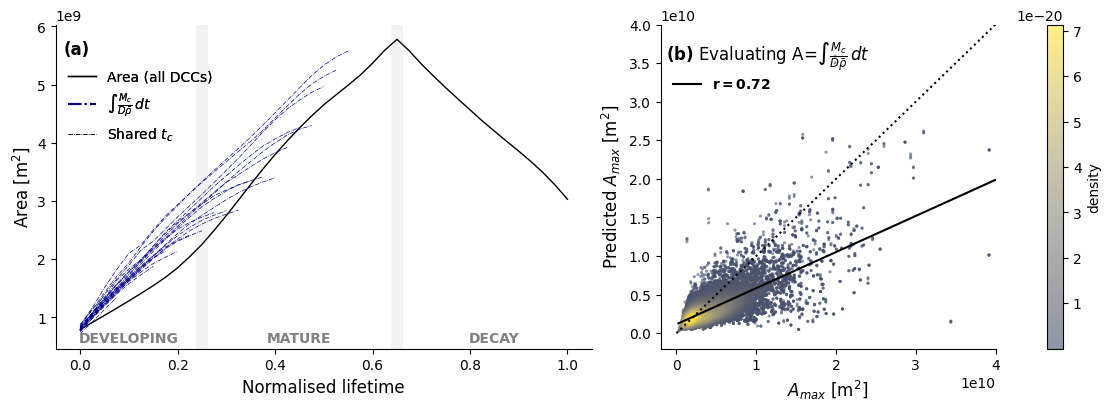

In [85]:

model_names = ("Apred_v2", )

# figure
widths = [4, 2.5]
fig = plt.figure(figsize=(11,4), layout='constrained')
gs = fig.add_gridspec(1, len(widths), width_ratios=widths, wspace=0)
axs = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1])]

# -- first axis --
ax = axs[0]
A_mu = ds.cloud_area.mean("system")
h0 = plot_helpers.get_evolution(A_mu).plot(ax=ax, c="k", zorder=1, lw=1, label="Area (all DCCs)")

line_colors = ["darkblue"]
line_styles = ["-."] * 2

for i, model in enumerate(model_names):
    mean_predictions, n_samples = get_predictions_by_their_endpoint(model)
    label = global_labels[model]
    
    for period in mean_predictions.period.values:
        n = n_samples.sel(period=period)
        if n < 30 or period > .55:
            continue
        d = mean_predictions.sel(period=period)
        d.plot(ax=ax, lw=0.5, c=line_colors[i], ls=line_styles[i], zorder=1, label=label)
        label = None

plot_helpers.show_phases(ax, ax.get_ylim()[1] * 0.125)
ax.set_xlabel("Normalised lifetime", fontsize=fs)
ax.set_ylabel("Area [m$^2$]", fontsize=fs)
ax.set_title(None)
ax.text(
    0.015,
    0.95,
    "(a)",
    transform=ax.transAxes,
    c="k",
    weight="bold",
    fontsize=fs,
    va="top",
)

h1 = mpl.lines.Line2D([], [], color=line_colors[0], ls=line_styles[0], label=global_labels[model_names[0]])
# h2 = mpl.lines.Line2D([], [], color=line_colors[1], ls=line_styles[1], label=global_labels[model_names[1]])
h3 = mpl.lines.Line2D([], [], color="k", ls=line_styles[0], lw=.5, label="Shared $t_c$")
legend = ax.legend(handles=[h0[0],h1,h3], loc="upper left", bbox_to_anchor=(0.0, 0.9), frameon=False, fontsize=fs - 2, ncol=1)
ax.add_artist(legend)

# -- second axis --

ax = axs[1]
model = "Apred_v2"

extent = (0, 4e10, 0, 4e10)
max_extent = extent[1]
hexbin_params = dict(gridsize=40, mincnt=1, reduce_C_function=np.sum, extent=extent,)
tparams = dict(c='k', va='top')

hcmap = mpl.colors.ListedColormap(plt.get_cmap("cividis")(np.linspace(0.25, 1, 256)))
norm = mpl.colors.Normalize(vmin=0, vmax=250)

true = ds.cloud_area.max("interp_time")
pred = ds[model].max("interp_time")

x, y, xline, yline, result = helpers.evaluate_predictions(true, pred, dict(alternative="two-sided"))
rscore, slope, p = result.rvalue, result.slope, result.pvalue

# compute KDE density at each point
xy = np.vstack([x, y])
density = scipy.stats.gaussian_kde(xy)(xy)
order = density.argsort() # sort by density so densest points plot on top
x_s, y_s, d_s = x[order], y[order], density[order]
sc = ax.scatter(x_s, y_s, c=d_s, cmap=HCMAP, s=5, alpha=0.6, rasterized=True, linewidths=0)
ax.plot([0, max_extent], [0, max_extent], c="k", ls=":")

mask = (xline <= max_extent) & (yline <= max_extent)
label = rf"$\mathbf{{r={rscore:.2f}}}$" if p < 0.05 else rf"r={rscore:.2f}"
ax.plot(xline[mask], yline[mask], c='k', ls="-", label=label, lw=1.5)

ax.set_xlim(-0.05*max_extent, max_extent)
ax.set_ylim(-0.05*max_extent, max_extent)
plt.colorbar(sc, ax=ax, label='density')
ax.set_ylabel("Predicted $A_{max}$ [m$^2$]", fontsize=fs)
ax.set_xlabel("$A_{max}$ [m$^2$]", fontsize=fs)
ax.legend(frameon=0, loc="upper left", bbox_to_anchor=(0,0.875), fontsize=fs-2)
ax.text(0.015,0.95,f"$\mathbf{{(b)}}$ Evaluating A={global_labels[model]}", transform=ax.transAxes, 
        fontsize=fs, va='top')
ax.set_title(None)

for i, ax in enumerate(axs):
    ax.spines[['top', 'right']].set_visible(False)

fig.savefig(paperdir / f"fig04.{ext}", bbox_inches="tight", dpi=dpi)

##### NEW

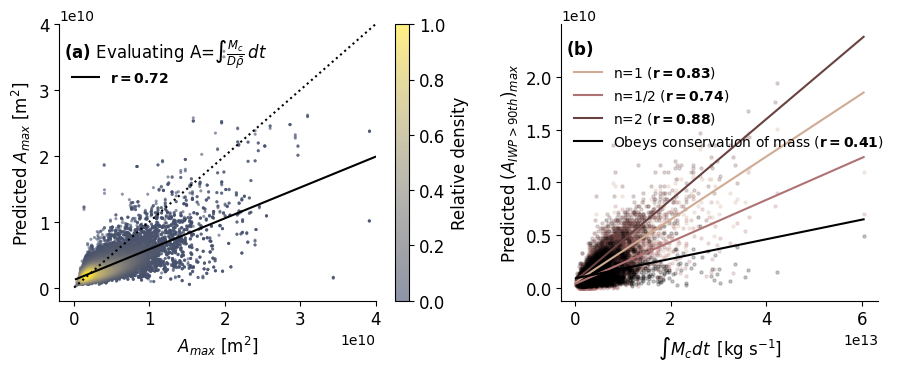

In [107]:
# figure

model = "Apred_v2"

fig = plt.figure(figsize=(9, 3.5))
gs = fig.add_gridspec(1, 2, width_ratios=[2.5,2], wspace=0.25, hspace=0.05,
                      left=0.07, right=0.98, top=0.97, bottom=0.18)

axs = [fig.add_subplot(gs[0, i]) for i in range(2)]

def panel_label(ax, letter, text=''):
    label = f"$\\mathbf{{({letter})}}$" + (f" {text}" if text else '')
    ax.text(0.015, 0.95, label, transform=ax.transAxes, fontsize=fs, va='top')

# -- panel (b) --
ax = axs[0]
max_extent = 4e10
extent = (0, max_extent, 0, max_extent)

true = ds.cloud_area.max("interp_time")
pred = ds[model].max("interp_time")
x, y, xline, yline, result = helpers.evaluate_predictions(true, pred, dict(alternative="two-sided"))
rscore, slope, p = result.rvalue, result.slope, result.pvalue

density = scipy.stats.gaussian_kde(np.vstack([x, y]))(np.vstack([x, y]))
density = (density - density.min()) / (density.max() - density.min())
order = density.argsort()
sc = ax.scatter(x[order], y[order], c=density[order], cmap=HCMAP,
                s=5, alpha=0.6, rasterized=True, linewidths=0)

ax.plot([0, max_extent], [0, max_extent], c="k", ls=":")
mask = (xline <= max_extent) & (yline <= max_extent)
rlabel = rf"$\mathbf{{r={rscore:.2f}}}$" if p < 0.05 else rf"r={rscore:.2f}"
ax.plot(xline[mask], yline[mask], c='k', ls="-", lw=1.5, label=rlabel)

ax.set(xlim=(-0.05*max_extent, max_extent), ylim=(-0.05*max_extent, max_extent),
       xlabel="$A_{max}$ [m$^2$]", ylabel="Predicted $A_{max}$ [m$^2$]", title=None)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.875), fontsize=fs-2)
panel_label(ax, 'a', f"Evaluating A={global_labels[model]}")

cb = plt.colorbar(sc, ax=ax, orientation='vertical', label='Relative density')
cb.ax.tick_params(labelsize=fs)
cb.set_label('Relative density', fontsize=fs)

# -- panel (c) --
ax = axs[1]
cmap = plt.get_cmap('pink_r')
di = {
    1:  [n1,  dict(label='n=1', c=cmap(.5))],
    .5: [n12, dict(label='n=1/2', c=cmap(.7))],
    2:  [n2,  dict(label='n=2', c=cmap(.9))],
    0:  [n0,  dict(label='Obeys conservation of mass', c='k')],
}
scatter_params = dict(s=5, alpha=.2)

for k, (n, kw) in di.items():
    c, label = kw['c'], kw['label']
    Ax = n.thick_A.max('interp_time').isel(threshold=8)
    x, y = ds.total_CMT.values, Ax.where(Ax > 1e6).values

    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    lo, hi = np.percentile(x, [0, 100])
    pm = (x >= lo) & (x <= hi)
    
    ax.scatter(x[pm], y[pm], c=c, **scatter_params)
    m, b, r, p, _ = scipy.stats.linregress(x[pm], y[pm])
    rlabel = rf"$(\mathbf{{r={r:.2f}}}$)" if p < 0.05 else rf"(r={r:.2f})"
    ax.plot([lo, hi], m * np.array([lo, hi]) + b, c=c, lw=1.5, label=f"{label} {rlabel}")

ax.set(xlabel=global_labels['total_CMT'], ylabel='Predicted ($A_{IWP>90th}$)$_{max}$')
ax.legend(frameon=False, fontsize=fs-2, loc='upper left', bbox_to_anchor=(0,.9))
panel_label(ax, 'b')

for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=fs)
    ax.xaxis.label.set_fontsize(fs)
    ax.yaxis.label.set_fontsize(fs)

fig.savefig(paperdir / f"fig05.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


##### THREE PANELS

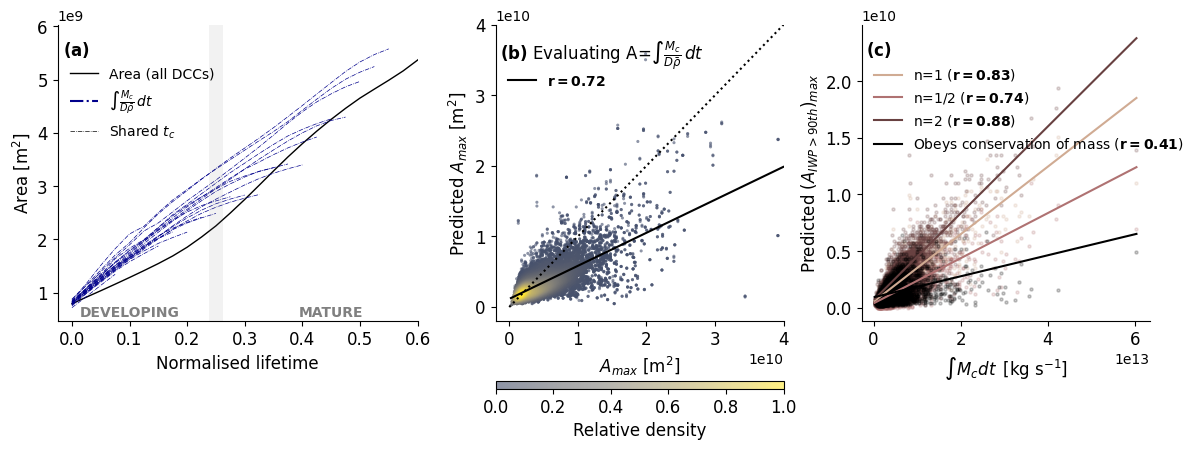

In [100]:
# figure

model = "Apred_v2"

fig = plt.figure(figsize=(12, 4))
gs = fig.add_gridspec(2, 3, width_ratios=[2.5,2,2], wspace=0.25, hspace=0.05,
                      left=0.07, right=0.98, top=0.97, bottom=0.18,
                      height_ratios=[1, 0.04])

axs = [fig.add_subplot(gs[0, i]) for i in range(3)]

def panel_label(ax, letter, text=''):
    label = f"$\\mathbf{{({letter})}}$" + (f" {text}" if text else '')
    ax.text(0.015, 0.95, label, transform=ax.transAxes, fontsize=fs, va='top')

# -- panel (a) --
ax = axs[0]
c, ls = "darkblue", "-."

A_mu = ds.cloud_area.mean("system")
h0 = plot_helpers.get_evolution(A_mu).plot(ax=ax, c="k", zorder=1, lw=1, label="Area (all DCCs)")

mean_predictions, n_samples = get_predictions_by_their_endpoint(ds, model)
first_label = global_labels[model]
for period in mean_predictions.period.values:
    if n_samples.sel(period=period) < 30 or period > .55:
        continue
    mean_predictions.sel(period=period).plot(ax=ax, lw=0.5, c=c, ls=ls, zorder=1, label=first_label)
    first_label = None

plot_helpers.show_phases(ax, ax.get_ylim()[1] * 0.125, show_decay=False)
ax.set(xlabel="Normalised lifetime", ylabel="Area [m$^2$]", title=None, xlim=(-.025, .6))
ax.legend(handles=[h0[0],
                   mpl.lines.Line2D([], [], color=c, ls=ls, label=global_labels[model]),
                   mpl.lines.Line2D([], [], color="k", ls=ls, lw=.5, label="Shared $t_c$")],
          loc="upper left", bbox_to_anchor=(0.0, 0.9), frameon=False, fontsize=fs-2)
panel_label(ax, 'a')

# -- panel (b) --
ax = axs[1]
max_extent = 4e10
extent = (0, max_extent, 0, max_extent)

true = ds.cloud_area.max("interp_time")
pred = ds[model].max("interp_time")
x, y, xline, yline, result = helpers.evaluate_predictions(true, pred, dict(alternative="two-sided"))
rscore, slope, p = result.rvalue, result.slope, result.pvalue

density = scipy.stats.gaussian_kde(np.vstack([x, y]))(np.vstack([x, y]))
density = (density - density.min()) / (density.max() - density.min())
order = density.argsort()
sc = ax.scatter(x[order], y[order], c=density[order], cmap=HCMAP,
                s=5, alpha=0.6, rasterized=True, linewidths=0)

ax.plot([0, max_extent], [0, max_extent], c="k", ls=":")
mask = (xline <= max_extent) & (yline <= max_extent)
rlabel = rf"$\mathbf{{r={rscore:.2f}}}$" if p < 0.05 else rf"r={rscore:.2f}"
ax.plot(xline[mask], yline[mask], c='k', ls="-", lw=1.5, label=rlabel)

ax.set(xlim=(-0.05*max_extent, max_extent), ylim=(-0.05*max_extent, max_extent),
       xlabel="$A_{max}$ [m$^2$]", ylabel="Predicted $A_{max}$ [m$^2$]", title=None)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.875), fontsize=fs-2)
panel_label(ax, 'b', f"Evaluating A={global_labels[model]}")

fig.canvas.draw()
pos = axs[1].get_position()
cax = fig.add_axes([pos.x0, 0.06, pos.width, 0.02])
cb = fig.colorbar(sc, cax=cax, orientation='horizontal', label='Density')
cb.ax.tick_params(labelsize=fs)
cb.set_label('Relative density', fontsize=fs)

# -- panel (c) --
ax = axs[2]
cmap = plt.get_cmap('pink_r')
di = {
    1:  [n1,  dict(label='n=1', c=cmap(.5))],
    .5: [n12, dict(label='n=1/2', c=cmap(.7))],
    2:  [n2,  dict(label='n=2', c=cmap(.9))],
    0:  [n0,  dict(label='Obeys conservation of mass', c='k')],
}
scatter_params = dict(s=5, alpha=.2)

for k, (n, kw) in di.items():
    c, label = kw['c'], kw['label']
    Ax = n.thick_A.max('interp_time').isel(threshold=8)
    x, y = ds.total_CMT.values, Ax.where(Ax > 1e6).values

    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]
    lo, hi = np.percentile(x, [0, 100])
    pm = (x >= lo) & (x <= hi)
    
    ax.scatter(x[pm], y[pm], c=c, **scatter_params)
    m, b, r, p, _ = scipy.stats.linregress(x[pm], y[pm])
    rlabel = rf"$(\mathbf{{r={r:.2f}}}$)" if p < 0.05 else rf"(r={r:.2f})"
    ax.plot([lo, hi], m * np.array([lo, hi]) + b, c=c, lw=1.5, label=f"{label} {rlabel}")

ax.set(xlabel=global_labels['total_CMT'], ylabel='Predicted ($A_{IWP>90th}$)$_{max}$')
ax.legend(frameon=False, fontsize=fs-2, loc='upper left', bbox_to_anchor=(0,.9))
panel_label(ax, 'c')

for ax in axs:
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=fs)
    ax.xaxis.label.set_fontsize(fs)
    ax.yaxis.label.set_fontsize(fs)

fig.savefig(paperdir / f"fig05b.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)


#### FIGURE 5.2

##### PREPARE IDEALISED MODEL INPUTS

In [44]:
# idealised thickness model

# model choice (for area)
A_model = "Apred_v2_cont"

# input values
model_data = pds[['cloud_area', 'thick_area', 'Apred_v1_cont', 'Apred_v2_cont', 'core_rho_ABH', 'core_area_ABH', 'Apred_v2',
                 'core_fwc_ABH', 'core_cmt_ABH', 'anvil_depth_mu', 'anvil_rho_mu', 'lifetime','total_CMT', 'Apred_v1']]
model_data = model_data.where(model_data[A_model].max(('phase','interp_time'))>1e5)

In [45]:
# input data

quantiles = model_data.total_CMT.quantile(np.arange(0.05, 1, 0.1))
binned_data = model_data.groupby_bins(model_data.total_CMT, bins=quantiles).mean()

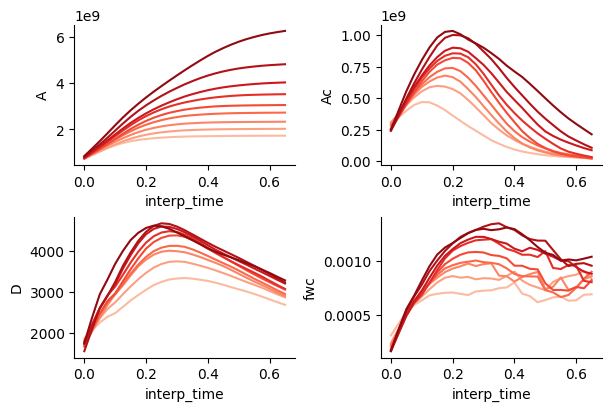

In [46]:

A = binned_data[A_model]
Ac = binned_data.core_area_ABH
D = binned_data.anvil_depth_mu
fwc = binned_data.core_fwc_ABH
    
fig, axs = plt.subplots(2, 2, figsize=(6, 4), layout='constrained')
axs = axs.flat

for i, (v, name) in enumerate(zip([A, Ac, D, fwc], ['A', 'Ac', 'D', 'fwc'])):
    for j, b in enumerate(v.total_CMT_bins.values):
        v.sel(total_CMT_bins=b, phase='growing').plot(ax=axs[i], c=CMAP(j/v.total_CMT_bins.size))

    axs[i].set_title(None)
    axs[i].set_ylabel(name)
    axs[i].spines[['top', 'right']].set_visible(False)

# axs[2].set_xlabel('total_CMT')
# axs[3].set_xlabel('total_CMT')

# fig.savefig(paperdir / f"fig04.{ext}", bbox_inches="tight", dpi=dpi)


##### RUN IDEALISED MODEL

In [47]:
# model runs

tau = 1
iwp_thresholds = ds.threshold.values

n0 = analytical.Thickness(binned_data, pred=A_model, n=0, tau=tau, xs=iwp_thresholds, )
n1 = analytical.Thickness(binned_data, pred=A_model, n=1, tau=tau, xs=iwp_thresholds, )
n12 = analytical.Thickness(binned_data, pred=A_model, n=1/2, tau=tau, xs=iwp_thresholds, )
n2 = analytical.Thickness(binned_data, pred=A_model, n=2, tau=tau, xs=iwp_thresholds, )

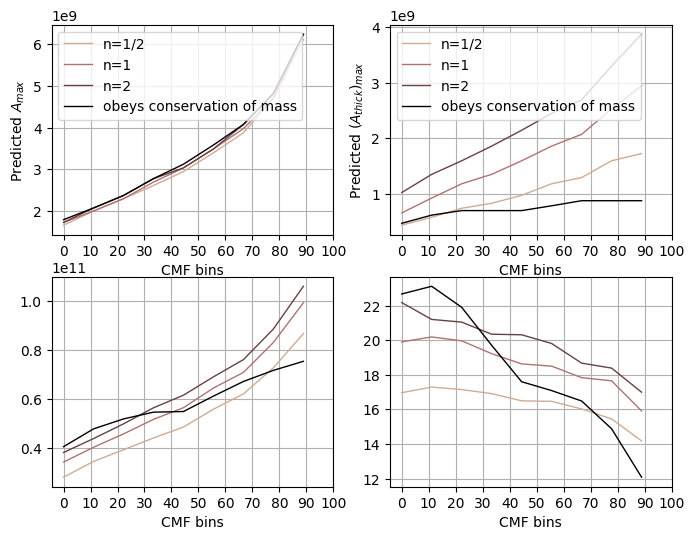

In [49]:
fig, axs = plt.subplots(2,2, figsize=(8,6))
axs = axs.flat

cmap = plt.get_cmap('pink_r')
m = None
di = {
    .5: [n12, dict(label='n=1/2', c=cmap(.5), marker=m)],
    1: [n1, dict(label='n=1', c=cmap(.7), marker=m)],
    2: [n2, dict(label='n=2', c=cmap(.9), marker=m)],
    0: [n0, dict(label='obeys conservation of mass', c='k', marker=m)],
     }
order = di.keys()

for ax,x in zip(axs[:2], [0,8]):
    for i,k in enumerate(order):
        version = di[k]
        n, params = version
        frac = n.thick_A.max(('interp_time',)).isel(threshold=x)
        ax.plot(frac, lw=1, **params)
        
    ax.legend()

axs[0].set_ylabel(r'Predicted $A_{max}$')
axs[1].set_ylabel(r'Predicted $(A_{thick})_{max}$')

for i,k in enumerate(order):
    version = di[k]
    n, params = version
    A0 = n.thick_A.max(('interp_time',)).isel(threshold=0)
    Ax = n.thick_A.max(('interp_time',)).isel(threshold=5)
    At = n.thick_A.sum(('interp_time',)).isel(threshold=5)
    axs[2].plot(At, lw=1, **params)
    axs[3].plot(At / A0, lw=1, **params)

for ax in axs:
    ax.grid()
    N = frac.total_CMT_bins.size
    ax.set_xticks(np.linspace(0,N,11), np.linspace(0,100,11).astype(int))
    ax.set_xlabel('CMF bins')


In [51]:
# model runs

tau = 1
iwp_thresholds = ds.threshold.values

n0 = analytical.Thickness(model_data, pred=A_model, n=0, tau=tau, xs=iwp_thresholds, )
n1 = analytical.Thickness(model_data, pred=A_model, n=1, tau=tau, xs=iwp_thresholds, )
n12 = analytical.Thickness(model_data, pred=A_model, n=1/2, tau=tau, xs=iwp_thresholds, )
n2 = analytical.Thickness(model_data, pred=A_model, n=2, tau=tau, xs=iwp_thresholds, )

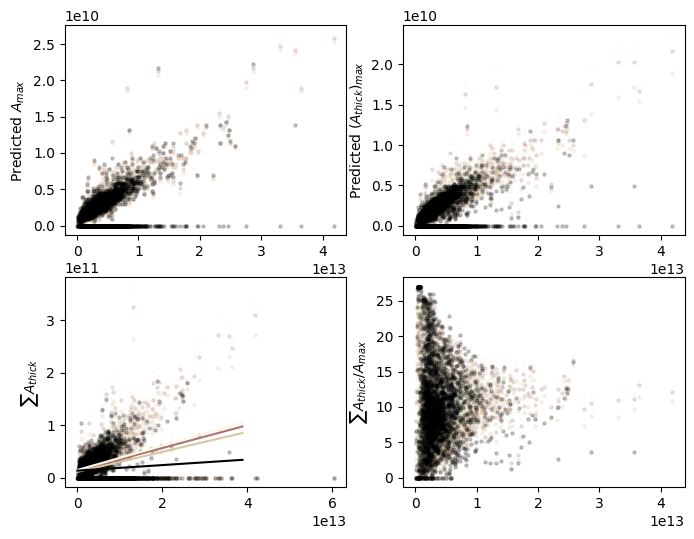

In [37]:
fig, axs = plt.subplots(2,2, figsize=(8,6))
axs = axs.flat

cmap = plt.get_cmap('pink')
params = dict(marker=None, s=5, alpha=.2)
di = {1: [n1, dict(label='n=1', c=cmap(.3), **params)],
      .5: [n12, dict(label='n=1/2', c=cmap(.6), **params)],
      2: [n2, dict(label='n=2', c=cmap(.9), **params)],
      0: [n0, dict(label='obeys conservation of mass', c='k', **params)],
     }
ylabels = [
    r'Predicted $A_{max}$',
    r'Predicted $(A_{thick})_{max}$',
    r'$\sum A_{thick}$',
    r'$\sum A_{thick} / A_{max}$',
]

for i,k in enumerate(di.keys()):
    version = di[k]
    n, params = version
    c = params['c']
    A0 = n.thick_A.max(('interp_time',)).isel(threshold=0)
    Ax = n.thick_A.max(('interp_time',)).isel(threshold=5)
    At = n.thick_A.sum(('interp_time',)).isel(threshold=5)
    A0t = n.thick_A.sum(('interp_time',)).isel(threshold=0)

    for j,y in enumerate([A0, Ax, At, At/A0]):
        ax = axs[j]
        x = ds.total_CMT
        ax.scatter(x, y, **params)

        lo, hi = np.percentile(x, [0, 99.95])
        pm = (x >= lo) & (x <= hi)
        m, b, r, p, _ = scipy.stats.linregress(x[pm], y[pm])
        x_fit = np.array([lo, hi])
        rlabel = rf"$\mathbf{{r={r:.2f}}}$" if p < 0.05 else rf"r={r:.2f}"
        ax.plot(x_fit, m * x_fit + b, c=c, lw=1.5, label=f"{label} {rlabel}")

for i, ax in enumerate(axs):
    ax.set_ylabel(ylabels[i])
    ax.set_xlabel('')

    

In [224]:
for k, (n, kw) in di.items():
    print(k, n.thick_A.isel(threshold=8).max('interp_time').mean().values)

0.5 1265611584.1901097
1 1847713898.3271136
2 2371695670.167762
0 897917166.5567759


In [216]:
kw['c']

'k'

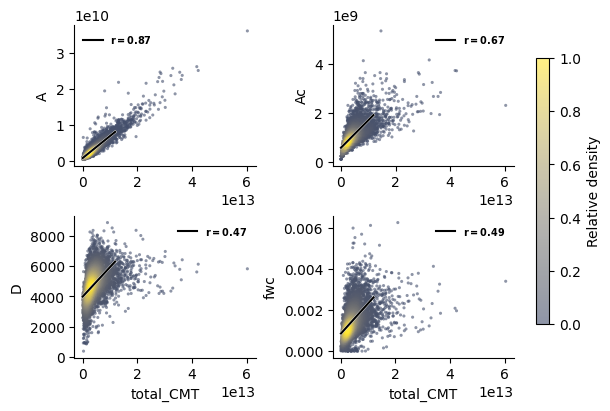

In [50]:
# scalar inputs
scalar_data = model_data.sel(phase='overall').max('interp_time')

A = scalar_data[A_model]
Ac = scalar_data.core_area_ABH
D = scalar_data.anvil_depth_mu
fwc = scalar_data.core_fwc_ABH

fig, axs = plt.subplots(2, 2, figsize=(6, 4), layout='constrained')
axs = axs.flat

for i, (v, name) in enumerate(zip([A, Ac, D, fwc], ['A', 'Ac', 'D', 'fwc'])):
    x = model_data.total_CMT.values
    y = v.values if hasattr(v, 'values') else np.array(v)

    mask = np.isfinite(x) & np.isfinite(y)
    x, y = x[mask], y[mask]

    density = scipy.stats.gaussian_kde(np.vstack([x, y]))(np.vstack([x, y]))
    density = (density - density.min()) / (density.max() - density.min())
    order = density.argsort()

    sc = axs[i].scatter(x[order], y[order], c=density[order], s=5,
                        cmap=HCMAP, alpha=0.6, rasterized=True, linewidths=0)

    lo, hi = np.percentile(x, [0, 95])
    mask_pct = (x >= lo) & (x <= hi)
    m, b, r, p, _ = scipy.stats.linregress(x[mask_pct], y[mask_pct])
    x_fit = np.array([lo, hi])
    label = rf"$\mathbf{{r={r:.2f}}}$" if p < 0.05 else rf"r={r:.2f}"
    axs[i].plot(x_fit, m * x_fit + b, c='w', lw=2)
    axs[i].plot(x_fit, m * x_fit + b, c='k', lw=1.5, label=label)

    axs[i].set_ylabel(name)
    axs[i].legend(fontsize=7, frameon=False)
    axs[i].spines[['top', 'right']].set_visible(False)

axs[2].set_xlabel('total_CMT')
axs[3].set_xlabel('total_CMT')

fig.colorbar(sc, ax=list(axs), label='Relative density', shrink=.8)
# fig.savefig(paperdir / f"fig04.{ext}", bbox_inches="tight", dpi=dpi)


In [178]:
# data
model_data = ds[['cloud_area', 'thick_area', 'Apred_v1_cont', 'Apred_v2_cont', 'core_rho_ABH', 'core_area_ABH', 'Apred_v2',
                 'core_fwc_ABH', 'core_cmt_ABH', 'anvil_depth_mu', 'anvil_rho_mu', 'lifetime','total_CMT', 'Apred_v1']]
model_data_by_inflow = helpers.group_dataset_by_intensity(model_data, df)[key]

# model choice for area evolution
A_model = "Apred_v2_cont"

In [179]:
# input values, averaged within each inflow quartile
broadcast = model_data.cloud_area.mean('system')
A = model_data_by_inflow[A_model]
Ac = model_data_by_inflow.core_area_ABH
D = model_data_by_inflow.anvil_depth_mu
fwc = model_data_by_inflow.core_fwc_ABH

In [180]:
# best case (everything varies)

n = 1
tau = 1
iwp_thresholds = ds.threshold.values

best = analytical.Thickness(model_data_by_inflow, pred=A_model, n=n, tau=tau, xs=iwp_thresholds, )

n0 = analytical.Thickness(model_data_by_inflow, pred=A_model, n=0, tau=tau, xs=iwp_thresholds, )
n1 = analytical.Thickness(model_data_by_inflow, pred=A_model, n=1, tau=tau, xs=iwp_thresholds, )
n12 = analytical.Thickness(model_data_by_inflow, pred=A_model, n=1/2, tau=tau, xs=iwp_thresholds, )
n2 = analytical.Thickness(model_data_by_inflow, pred=A_model, n=2, tau=tau, xs=iwp_thresholds, )

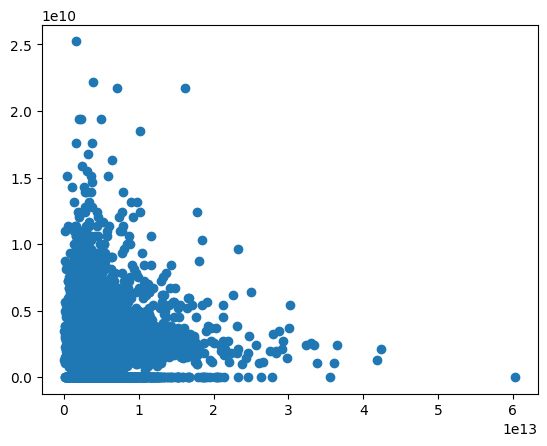

In [195]:
fig, ax = plt.subplots()

Mc = ds.total_CMT
A = n.thick_A.max(('interp_time','bins')).isel(threshold=0)
Ax = n.thick_A.max(('interp_time','bins')).isel(threshold=8)

ax.scatter(Mc, A)

Text(0, 0.5, 'Predicted $(A_{thick})_{max}$ / $A_{max}$')

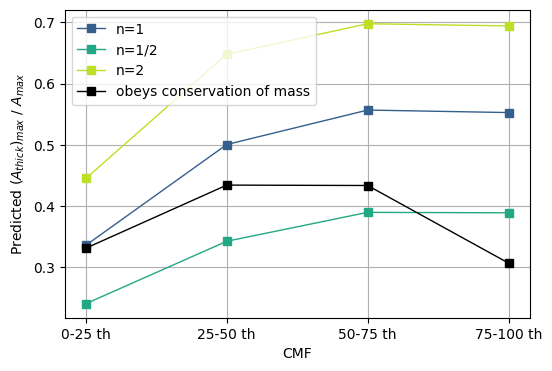

In [183]:
fig, ax = plt.subplots(figsize=(6,4))

cmap = plt.get_cmap('viridis')
m = 's'
di = {1: [n1, dict(label='n=1', c=cmap(.3), marker=m)],
      .5: [n12, dict(label='n=1/2', c=cmap(.6), marker=m)],
      2: [n2, dict(label='n=2', c=cmap(.9), marker=m)],
      0: [n0, dict(label='obeys conservation of mass', c='k', marker=m)],
     }
order = [1, .5, 2, 0]

N = len(iwp_thresholds)
for i,k in enumerate(order):
    version = di[k]
    n, params = version
    
    d0 = n.thick_A.max(('interp_time',)).isel(threshold=0)
    d1 = n.thick_A.max(('interp_time',)).isel(threshold=8)
    frac = d1.mean('system') / d0.mean('system')
    # frac = d1 / d0
    ax.plot(frac, lw=1, **params)
    
ax.legend()
ax.grid()
ax.set_xticks(np.arange(0,4), [d0.bins.values[i] +' th' for i in range(4)])
ax.set_xlabel('CMF')
ax.set_ylabel(r'Predicted $(A_{thick})_{max}$ / $A_{max}$')


Text(0, 0.5, 'Predicted $(A_{thick})_{max}$')

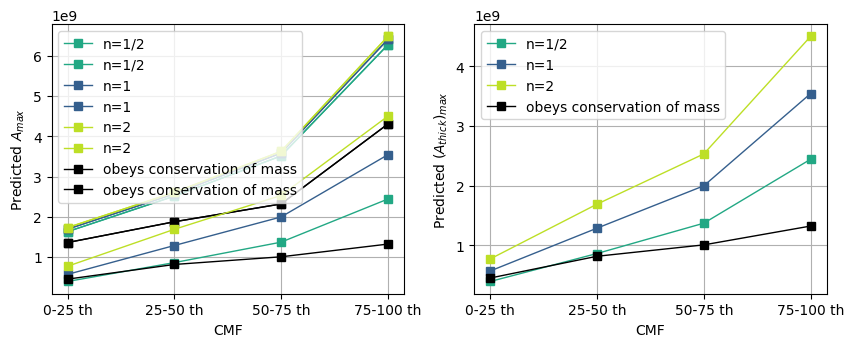

In [188]:
fig, axs = plt.subplots(1,2, figsize=(10,3.5))

cmap = plt.get_cmap('viridis')
m = 's'
di = {1: [n1, dict(label='n=1', c=cmap(.3), marker=m)],
      .5: [n12, dict(label='n=1/2', c=cmap(.6), marker=m)],
      2: [n2, dict(label='n=2', c=cmap(.9), marker=m)],
      0: [n0, dict(label='obeys conservation of mass', c='k', marker=m)],
     }
order = [.5, 1, 2, 0]

for ax,x in zip(axs, [0,8]):
    for i,k in enumerate(order):
        version = di[k]
        n, params = version
        frac = n.thick_A.max(('interp_time',)).isel(threshold=x).mean('system')
        ax.plot(frac, lw=1, **params)
        axs[0].plot(frac, lw=1, **params)
        
    ax.legend()
    ax.grid()
    ax.set_xticks(np.arange(0,4), [d0.bins.values[i] +' th' for i in range(4)])
    ax.set_xlabel('CMF')

axs[0].set_ylabel(r'Predicted $A_{max}$')
axs[1].set_ylabel(r'Predicted $(A_{thick})_{max}$')


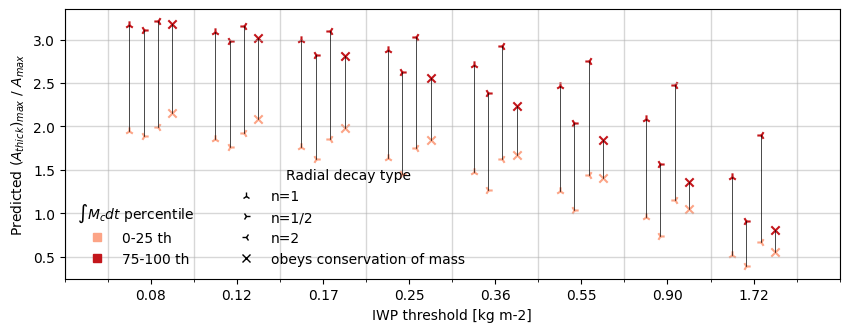

In [134]:
fig, ax = plt.subplots(figsize=(10,3.5))

di = {1: [n1, '2', 'n=1'],
      .5: [n12, '4', 'n=1/2'],
      2: [n2, '3', 'n=2'],
      0: [n0, 'x', 'obeys conservation of mass'],
     }
order = [1, .5, 2, 0]

N = len(iwp_thresholds)
for i,k in enumerate(order):
    version = di[k]
    n = version[0]
    shift = [-3/12, -1/12, 1/12, 3/12][i]
    
    for x in range(1,N):
        d0 = n.thick_A.max(('interp_time',)).isel(threshold=0)
        d1 = n.thick_A.max(('interp_time',)).isel(threshold=x)
        frac = d1.mean('system') / d0.mean('system')
    
        for j,b in enumerate([d0.bins.values[0], d0.bins.values[-1]]):
            c = [CMAP(0/5+.1), CMAP(3/5+.1)][j]
            ax.scatter(x+shift, frac.sel(bins=b), c=c, marker=version[1], alpha=1)
        ax.plot([x+shift]*2, [frac.isel(bins=0), frac.isel(bins=-1)], c='k', lw=.5)        

colors = [Line2D([0],[0], marker='s', ls="None", c=CMAP(i/5+.1), label=d0.bins.values[i] +' th',) for i in [0,3]]
legend1 = ax.legend(handles=colors, title=r"$\int M_c dt$ percentile", loc="lower left", frameon=0)
ax.add_artist(legend1)
shapes = [Line2D([0],[0], marker=di[k][1], ls="None", c="k", label=di[k][2],) for k in order]
legend2 = ax.legend(handles=shapes, title="Radial decay type", loc="lower left", bbox_to_anchor=(.2,0), frameon=0)

ax.set_xlabel('IWP threshold [kg m-2]')
ax.set_ylabel(r'Predicted $(A_{thick})_{max}$ / $A_{max}$')

ax.set_xticks(np.arange(1,N), [f"{x:.2f}" for x in iwp_thresholds[1:]])
ax.set_xticks(np.arange(0, N + .5, .5), minor=True)
ax.grid(True, which="minor", linewidth=1, alpha=0.5)
ax.grid(axis='y', linewidth=1, alpha=0.5)

# fig.savefig(paperdir / f"fig05.{ext}", bbox_inches="tight", dpi=dpi, transparent=True)
